# Wine Clustering: Finding Wine Styles in 130k Tasting Notes

Wine shops sort bottles by grape and country, but customers shop by taste: "crisp and citrusy", "big, oaky red", "something earthy". Wine Enthusiast tasters wrote a note for 130,000 wines. Can the words alone sort the wines into taste styles that cross grapes and borders? This notebook cleans the notes, removes every grape and country name so the model cannot cheat, groups the wines with four families of clustering, names each style from its words, and only then opens the answer key (the grape variety) to see how much of "style" is really "grape".

**Objectives**
1. What needs cleaning before 130k reviews can be compared?
2. Which words carry the taste, once grape and country names are removed?
3. How many taste styles are there, and which clustering family finds them best?
4. What does each style taste like, and what does it cost?
5. How much of a style is its grape, and where do grapes cross styles?
6. Which wines are good value inside each style?

**Data** → [Wine Reviews](https://www.kaggle.com/datasets/zynicide/wine-reviews) (Wine Enthusiast) · 129,971 reviews · tasting note, points (80-100), price, variety, country, winery

<!-- objective -->
## Objective

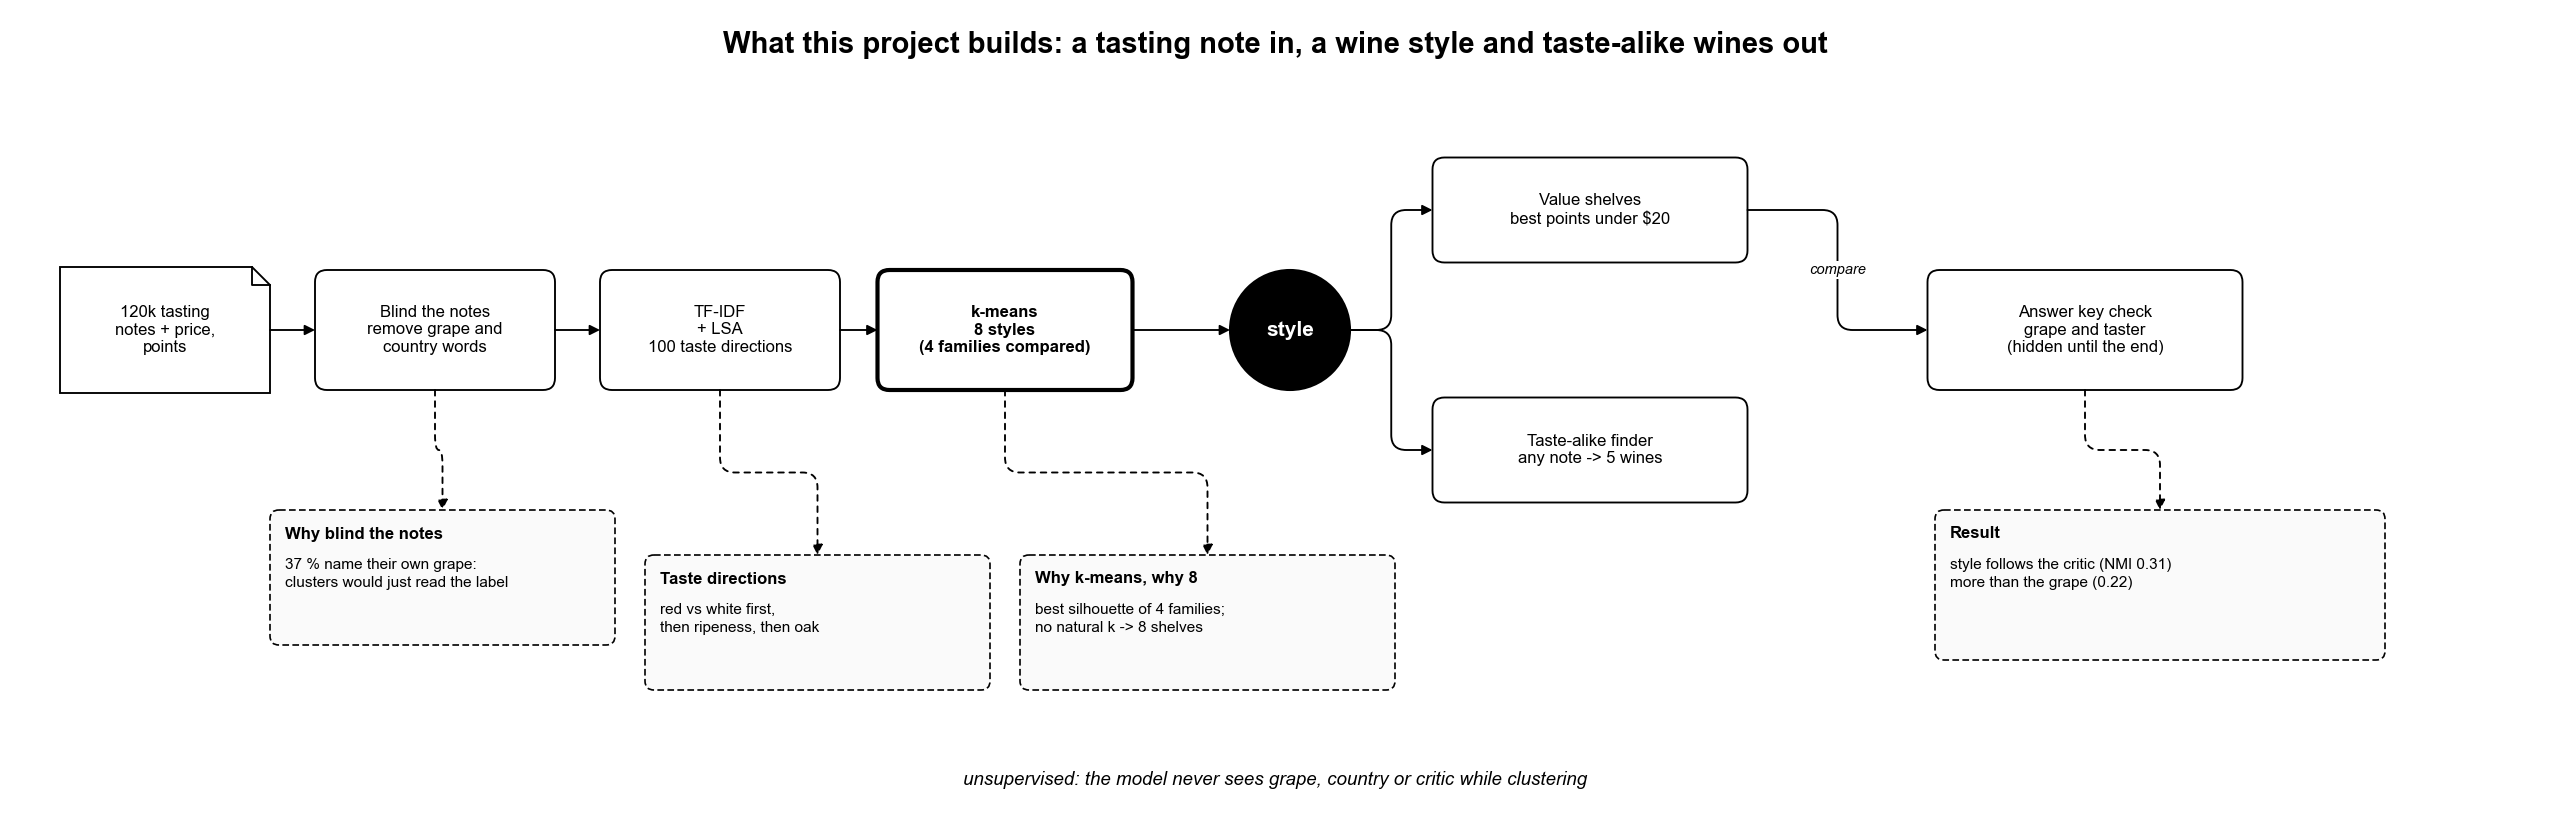

- **Problem** → shops and apps sort wine by grape and country, but people buy by taste ("crisp and citrusy", "big and oaky"), and a list of 700 grape names does not help them choose
- **Why this repo** → group 120k tasting notes into taste styles from the words alone (grape and country names removed), check how stable and how "grape-driven" the styles are, and find good value inside each style
- **Real-world use** → taste-based shelves and menus, "tastes like" suggestions across grapes and countries, and a value pick under $20 for every style

# [1/13] Setup

Set every knob once in the top cell → nothing is written and no app is started unless you switch it on

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/11] DATA_DIR: folder searched recursively for winemag-data-130k-v2.csv (falls back to /kaggle/input)
    Default = '/kaggle/input/datasets/zynicide/wine-reviews'
[2/11] WORK_DIR: folder for exported figures
    Default = '/kaggle/working'
[3/11] MAX_FEATURES: vocabulary size of the TF-IDF matrix (words and two-word phrases)
    Default = 20000
[4/11] N_COMPONENTS: LSA dimensions (truncated SVD of the TF-IDF matrix)
    Default = 100
[5/11] K_MAX: largest number of styles tried
    Default = 14
[6/11] K_FINAL: number of styles used after section 8 (text has no natural k, so this is a shelf-count choice)
    Default = 8
    For example:
        K_FINAL = 5
[7/11] EVAL_SAMPLE: reviews used for slow scores (silhouette, Ward, DBSCAN, stability)
    Default = 6000
[8/11] N_BOOT: bootstrap resamples for the stability check
    Default = 30
[9/11] VALUE_PRICE: price cap ($) for "good value" picks
    Default = 20
[10/11] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
[11/11] LAUNCH_APP: start the Gradio taste-alike finder at the end (public link on Kaggle)
    Default = False
"""
DATA_DIR     = '/kaggle/input/datasets/zynicide/wine-reviews'
WORK_DIR     = '/kaggle/working'
MAX_FEATURES = 20000
N_COMPONENTS = 100
K_MAX        = 14
K_FINAL      = 8
EVAL_SAMPLE  = 6000
N_BOOT       = 30
VALUE_PRICE  = 20
SAVE_FIGURES = False
LAUNCH_APP   = False

SEED         = 42
PAD          = 36
GREYS        = ['#000000', '#404040', '#808080', '#a0a0a0', '#c0c0c0', '#606060', '#202020', '#909090',
                '#b0b0b0', '#303030', '#707070', '#d0d0d0', '#505050', '#e0e0e0']

In [ ]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans, MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
ASSETS = Path(WORK_DIR) / 'assets'
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_reviews_csv(*roots):
    """The 130k review CSV (header with description, points and variety), searched recursively."""
    import csv
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        files = sorted(root.rglob('*.csv'), key=lambda f: ('130k' not in f.name, f.name))
        for f in files:
            with open(f, newline='', encoding='utf-8', errors='ignore') as fh:
                header = next(csv.reader(fh), [])
            if {'description', 'points', 'variety'} <= set(header):
                return f
    raise FileNotFoundError('(!) No wine-review CSV found. Add Input -> Datasets -> zynicide/wine-reviews')


def internal_scores(X, labels):
    mask = labels >= 0
    if len(set(labels[mask])) < 2:
        return {'silhouette (cosine)': np.nan, 'Calinski-Harabasz': np.nan, 'Davies-Bouldin': np.nan}
    return {'silhouette (cosine)': silhouette_score(X[mask], labels[mask], metric='cosine'),
            'Calinski-Harabasz': calinski_harabasz_score(X[mask], labels[mask]),
            'Davies-Bouldin': davies_bouldin_score(X[mask], labels[mask])}

# [2/13] Data

Load the reviews → one row per wine: tasting note, points, price, grape, place and taster

In [ ]:
csv_path = find_reviews_csv(DATA_DIR, '/kaggle/input')
raw = pd.read_csv(csv_path, index_col=0)
show_block('Outputs', {'file': csv_path.name, 'reviews': f'{len(raw):,}', 'columns': raw.shape[1],
                       'varieties': f'{raw["variety"].nunique():,}', 'countries': raw['country'].nunique(),
                       'tasters': raw['taster_name'].nunique()})

In [ ]:
display(raw[['title', 'variety', 'country', 'points', 'price', 'description']].head(3))

# [3/13] Data health

Remove repeated reviews, check gaps and the price tail → the table every later step uses

**Question:** What must be fixed before the reviews can be compared?

- **duplicates** → the same wine and the same note scraped twice would count double
- **missing price** → kept for text clustering, left out only of price analyses
- **points 80-100** → Wine Enthusiast publishes only wines it rates 80+, so "bad" wines are absent (a selection effect)
- Analogy → a restaurant guide that lists only the restaurants it liked

**Answer:** one repeat problem and a long price tail.
- 9,983 repeated reviews removed → 119,987 wines
- price missing for 7.0 %, taster for 20.8 %; prices run from $4 to $3,300 (median $25, 99th percentile $160) → log scale
- every wine scores 80-100 (median 88): only recommended wines are published

In [ ]:
dupes = raw.duplicated(['title', 'description'])
wine = raw[~dupes].dropna(subset=['description', 'variety']).reset_index(drop=True)
wine['log_price'] = np.log10(wine['price'])
health = pd.DataFrame({'missing %': (wine.isna().mean() * 100).round(1)}).query('`missing %` > 0')

In [ ]:
show_block('Outputs', {'repeated reviews removed': f'{dupes.sum():,}', 'reviews kept': f'{len(wine):,}',
                       'price: median / 99th pct / max': f'${wine["price"].median():.0f} / ${wine["price"].quantile(0.99):.0f} / ${wine["price"].max():,.0f}',
                       'points: min / median / max': f'{wine["points"].min()} / {wine["points"].median():.0f} / {wine["points"].max()}',
                       'words per note (median)': int(wine['description'].str.split().str.len().median())})
display(health)

# [4/13] EDA

Look at points, prices and the biggest grapes and countries → price buys points, but slowly

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(24, 5))
axes[0].hist(wine['points'], bins=np.arange(79.5, 101), color='grey')
axes[0].set(title='Points', xlabel='points')
sns.boxplot(data=wine.dropna(subset=['price']), x='points', y='price', color='lightgrey', fliersize=0, ax=axes[1])
axes[1].set(yscale='log', title='Price by points (log scale)', xlabel='points')
axes[1].tick_params(axis='x', rotation=90)
top_var = wine['variety'].value_counts().head(15)
axes[2].barh(top_var.index[::-1], top_var.values[::-1], color='black')
axes[2].set(title='15 most reviewed varieties', xlabel='reviews')
fig.tight_layout()
save(fig, '01_points_price')
plt.show()

In [ ]:
rho = spearmanr(wine['points'], wine['price'], nan_policy='omit')
priced = wine.dropna(subset=['price'])
slope = np.polyfit(priced['points'], priced['log_price'], 1)[0]
show_block('Outputs', {'Spearman points vs price': f'{rho.statistic:.3f}',
                       'price per extra point (median wine)': f'+{(10 ** slope - 1):.1%}',
                       'median price at 85 / 90 / 95 points': ' / '.join(f'${priced.loc[priced["points"] == p, "price"].median():.0f}' for p in (85, 90, 95)),
                       'top-5 varieties share of reviews': f'{top_var.head(5).sum() / len(wine):.1%}'})

**Question:** Does a higher price buy a better score?

$$\log_{10}(\text{price}) \approx a + b \cdot \text{points}$$
- the slope $b$ turns into "% more money per extra point": $10^{b} - 1$
- Spearman ρ → rank agreement, robust to the $3,300 bottles
- Analogy → each extra point costs a fixed percentage, like compound interest

**Answer:** yes, at a steep rate: each extra point costs about 14 % more (Spearman 0.61). The median bottle costs $16 at 85 points, $30 at 90 and $75 at 95.

# [5/13] Cleaning the notes

Remove grape, country and generic wine words → what remains is how the wine tastes

**Question:** Why remove grape and country names from the notes?

- many notes name the wine ("This Pinot Noir from Sonoma …"); clusters would simply sort by those words and rediscover the label
- removed → every word that appears in a variety or country name (pinot, noir, cabernet, blanc, rioja, california …), plus English stop words and generic wine words (wine, drink, flavors, finish)
- kept → taste and texture words: cherry, citrus, oak, tannins, crisp, earthy
- Analogy → blind tasting: the bottle is wrapped before anyone describes it

**Answer:** because 37 % of notes name their own grape. Removing 1,006 grape, country and region words (plus generic wine words) leaves a median of 18 taste words per note.

In [ ]:
def name_tokens(series):
    words = set()
    for name in series.dropna().unique():
        words |= {w for w in re.findall(r'[a-zà-ÿ]+', name.lower()) if len(w) > 2}
    return words


GENERIC = {'wine', 'wines', 'drink', 'drinks', 'flavors', 'flavor', 'aromas', 'aroma', 'finish', 'palate', 'nose', 'notes',
           'note', 'offers', 'shows', 'bottle', 'bottling', 'vintage', 'years', 'year', 'now', 'just', 'like', 'made', 'make',
           'feels', 'gives', 'hint', 'hints', 'touch', 'bit', 'quite', 'good', 'nice', 'well', 'mouth', 'mouthfeel', 'character'}
LEAKY = name_tokens(wine['variety']) | name_tokens(wine['country']) | name_tokens(wine['province'])
STOP = sorted(set(ENGLISH_STOP_WORDS) | GENERIC | LEAKY)
TOKEN = re.compile(r'[a-z]+')


def clean(text):
    return ' '.join(w for w in TOKEN.findall(text.lower()) if w not in STOP and len(w) > 2)


wine['clean'] = wine['description'].map(clean)
examples = wine.sample(3, random_state=SEED)[['variety', 'description', 'clean']]

In [ ]:
show_block('Outputs', {'grape / country / region words removed': f'{len(LEAKY):,}',
                       'reviews mentioning their own grape word': f'{wine.apply(lambda r: any(w in r["description"].lower() for w in name_tokens(pd.Series([r["variety"]]))), axis=1).mean():.1%}',
                       'words per note after cleaning (median)': int(wine['clean'].str.split().str.len().median())})
display(examples)

# [6/13] From words to numbers: TF-IDF and LSA

Weight every word by how specific it is, then compress to `N_COMPONENTS` taste directions → the first direction splits red from white

**Question:** What are the main taste directions in the notes?

$$\text{tf-idf}(w, d) = \text{tf}(w, d) \cdot \log\frac{N}{\text{df}(w)} \qquad X \approx U_k \Sigma_k V_k^\top$$
- rare, specific words ("petrol", "graphite") weigh more than common ones ("fruit")
- **LSA** → truncated SVD keeps the $k$ strongest word patterns; each review becomes $k$ numbers, normalised so that distance = cosine
- Analogy → describing a wine by a few sliders (red ↔ white, fresh ↔ ripe, oak ↔ none) instead of 20,000 words

**Answer:** red against white first, then ripeness and oak.
- direction 2 → cherry, tannins, blackberry vs crisp, acidity, citrus
- direction 3 → ripe, rich, wood, aging; direction 4 → oak, sweet, vanilla, chocolate vs bright, fresh
- 100 dimensions keep only 11 % of the variance: tasting notes are very diverse

In [ ]:
tfidf = TfidfVectorizer(max_features=MAX_FEATURES, ngram_range=(1, 2), min_df=5, sublinear_tf=True)
T = tfidf.fit_transform(wine['clean'])
svd = TruncatedSVD(N_COMPONENTS, random_state=SEED)
Z = normalize(svd.fit_transform(T))
terms = np.array(tfidf.get_feature_names_out())
directions = pd.DataFrame({f'LSA {i + 1}': [f'+ {", ".join(terms[np.argsort(svd.components_[i])[-6:][::-1]])}',
                                            f'- {", ".join(terms[np.argsort(svd.components_[i])[:6]])}'] for i in range(1, 5)},
                          index=['high end', 'low end']).T

In [ ]:
show_block('Outputs', {'TF-IDF matrix': f'{T.shape[0]:,} x {T.shape[1]:,}', 'non-zero share': f'{T.nnz / np.prod(T.shape):.4%}',
                       f'variance kept by {N_COMPONENTS} LSA dimensions': f'{svd.explained_variance_ratio_.sum():.1%}'})
display(directions)

# [7/13] A map of the notes

Project a sample of reviews onto the first two taste directions and colour them by the biggest grapes → reds and whites separate without being told

In [ ]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(wine), EVAL_SAMPLE, replace=False)
top8 = wine['variety'].value_counts().index[:8]
fig, ax = plt.subplots(figsize=(11, 7))
for i, v in enumerate(top8):
    m = sample_idx[wine['variety'].to_numpy()[sample_idx] == v]
    ax.scatter(Z[m, 1], Z[m, 2], s=8, alpha=0.6, color=GREYS[i], label=v, marker='o' if i < 4 else 'x')
ax.set(title='Reviews on LSA directions 2 and 3 (grape shown only for reading, never used to cluster)', xlabel='LSA 2', ylabel='LSA 3')
ax.legend(markerscale=2, fontsize=8)
save(fig, '02_lsa_map')
plt.show()

# [8/13] How many styles?

Score k = 2 … `K_MAX` with k-means on all reviews → pick the k where the rules agree and the styles can still be named

**Question:** How many taste styles are there?

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$$
- $a(i)$ → mean cosine distance to the own style, $b(i)$ → to the nearest other style (computed on `EVAL_SAMPLE` reviews)
- text clusters overlap, so silhouettes are small; if no rule shows a clear peak, k is a business choice (`K_FINAL` = how many shelves a shop can label)
- Analogy → sorting a library: too few shelves mix genres, too many split one genre across shelves

**Answer:** no natural number. Silhouettes stay between 0.05 and 0.07 for every k and no rule peaks, so k = 8 is a shelf-count choice: enough to separate whites, fresh reds, dark reds and oaky wines, few enough to label.

In [ ]:
rows = []
for k in range(2, K_MAX + 1):
    km = MiniBatchKMeans(k, n_init=5, batch_size=4096, random_state=SEED).fit(Z)
    lab = km.labels_
    rows.append({'k': k, 'inertia': km.inertia_, **internal_scores(Z[sample_idx], lab[sample_idx])})
k_scores = pd.DataFrame(rows).set_index('k')
gain = -k_scores['inertia'].diff() / k_scores['inertia'].shift()
K = K_FINAL or int(k_scores['silhouette (cosine)'].idxmax())

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(24, 4.5))
for ax, col in zip(axes, k_scores.columns):
    ax.plot(k_scores.index, k_scores[col], color='black', marker='o')
    ax.axvline(K, color='grey', linestyle='--')
    ax.set(title=col, xlabel='k')
fig.suptitle(f'Choosing the number of styles (dashed line: k = {K}, K_FINAL)', fontweight='bold')
fig.tight_layout()
save(fig, '03_choose_k')
plt.show()
display(pd.concat([k_scores, gain.rename('inertia drop')], axis=1).round(3))

# [9/13] Four families of clustering

Run one model from each family with k = `K` → compare separation and agreement with k-means

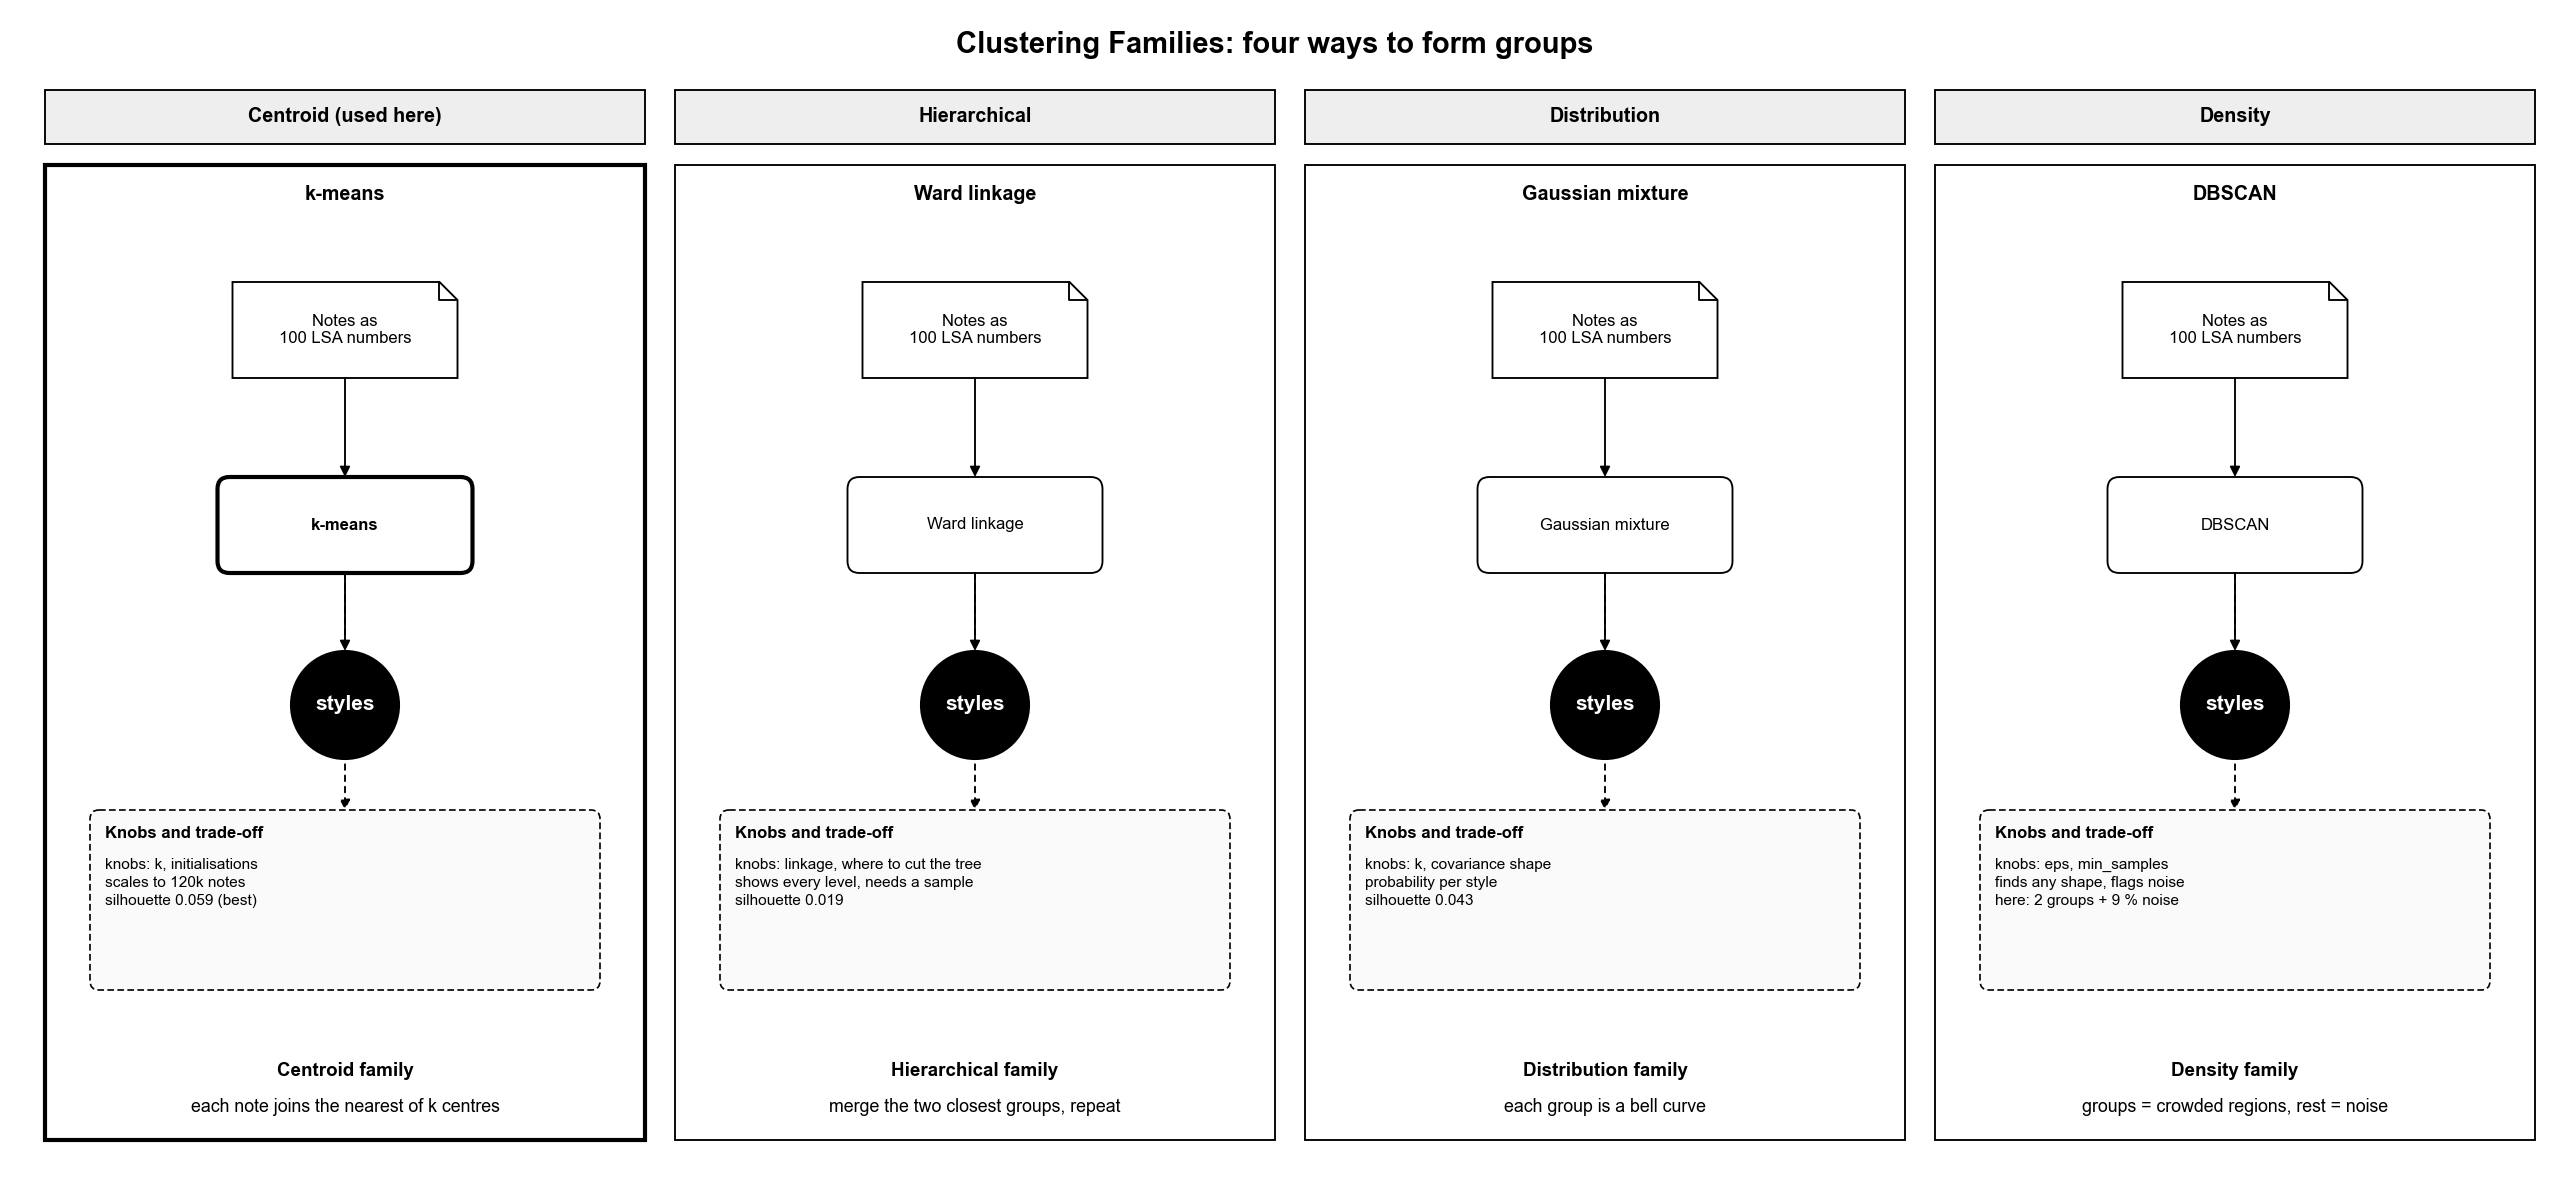

**Question:** Which family fits the notes best?

- **Centroid** (k-means, on all reviews) → each review joins the nearest style centre
- **Hierarchical** (Ward, on the sample) → merges the closest groups step by step
- **Distribution** (Gaussian mixture on the first 20 LSA dimensions) → a probability per style
- **Density** (DBSCAN, cosine) → crowded regions; isolated notes become noise
- Analogy → four ways to sort the same pile of tasting cards

**Answer:** k-means, clearly.
- silhouette 0.059 vs Gaussian mixture 0.043 and Ward 0.019; the other families agree with k-means only partly (ARI 0.39 and 0.24)
- DBSCAN finds 2 groups and 9 % noise: notes have no empty gaps between styles

In [ ]:
kmeans = KMeans(K, n_init=10, random_state=SEED).fit(Z)
labels_all = kmeans.labels_
Zs = Z[sample_idx]
eps_k = np.sort(NearestNeighbors(n_neighbors=10, metric='cosine').fit(Zs).kneighbors(Zs)[0][:, -1])
EPS = float(np.quantile(eps_k, 0.5))
families = {
    'k-means': labels_all[sample_idx],
    'Ward hierarchical': AgglomerativeClustering(K, linkage='ward').fit_predict(Zs),
    'Gaussian mixture': GaussianMixture(K, covariance_type='diag', n_init=3, random_state=SEED).fit(Z[:, :20]).predict(Zs[:, :20]),
    'DBSCAN': DBSCAN(eps=EPS, min_samples=10, metric='cosine').fit_predict(Zs),
}
family = pd.DataFrame({name: {'styles': len(set(l[l >= 0])), 'noise share': f'{(l < 0).mean():.0%}',
                              'agreement with k-means (ARI)': adjusted_rand_score(families['k-means'], l), **internal_scores(Zs, l)}
                       for name, l in families.items()}).T

In [ ]:
display(family)

# [10/13] Stability

Re-fit k-means on bootstrap resamples of the sample → do the same styles come back?

**Question:** Are the styles real, or an accident of one run?

- each resample: draw `EVAL_SAMPLE` reviews with replacement, fit k-means, give every sampled review its nearest new centre, compare with the full grouping (ARI)
- ARI 1 = the same styles every time, 0 = random
- Analogy → asking a second panel to sort the same cards

**Answer:** partly. The median ARI over 30 resamples is 0.41 (0.31-0.60): the big styles (citrus whites, dark-fruit reds) return every time, the borders between the smaller ones move.

In [ ]:
stab = []
for b in range(N_BOOT):
    idx = rng.choice(sample_idx, len(sample_idx), replace=True)
    km_b = KMeans(K, n_init=3, random_state=b).fit(Z[idx])
    stab.append(adjusted_rand_score(labels_all[sample_idx], km_b.predict(Zs)))
stab = pd.Series(stab, name='ARI')
show_block('Outputs', {'resamples': N_BOOT, 'median ARI': f'{stab.median():.3f}', 'range': f'{stab.min():.3f} - {stab.max():.3f}'})

# [11/13] What does each style taste like?

Read the strongest words of every style centre, plus its price and points → a name a wine seller can put on a shelf

In [ ]:
centres_terms = svd.inverse_transform(kmeans.cluster_centers_)
style_words = {g: [t for t in terms[np.argsort(centres_terms[g])[::-1]] if ' ' not in t][:6] for g in range(K)}
STYLE = {g: f'S{g + 1}: {", ".join(style_words[g][:3])}' for g in range(K)}
wine['style'] = [STYLE[g] for g in labels_all]
profile = wine.groupby('style').agg(reviews=('points', 'size'), median_points=('points', 'median'),
                                    median_price=('price', 'median'), top_variety=('variety', lambda s: s.value_counts().index[0]),
                                    top_variety_share=('variety', lambda s: s.value_counts(normalize=True).iloc[0]),
                                    top_country=('country', lambda s: s.value_counts().index[0]),
                                    top_taster=('taster_name', lambda s: s.value_counts().index[0] if s.notna().any() else '-'),
                                    top_taster_share=('taster_name', lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan))
profile['typical words'] = [', '.join(style_words[int(s.split(':')[0][1:]) - 1]) for s in profile.index]

In [ ]:
display(profile.sort_values('reviews', ascending=False).round(2))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 6))
order = profile.sort_values('median_price').index
axes[0].barh(order, profile.loc[order, 'reviews'], color='grey')
axes[0].set(title='Reviews per style', xlabel='reviews')
sns.boxplot(data=wine.dropna(subset=['price']), y='style', x='price', order=order, color='lightgrey', fliersize=0, ax=axes[1])
axes[1].set(xscale='log', title='Price by style (log scale)', ylabel='')
fig.tight_layout()
save(fig, '04_styles')
plt.show()

**Question:** How would a wine seller describe each style?

- each style is named by the strongest words of its centre (back-projected from LSA to words)
- the table adds what the style costs, how it scores, and which grape and country dominate it
- Analogy → shelf labels written from the tasters' own words

**Answer:** five taste styles and three writer styles.
- taste → dark-fruit reds (32,504 wines, $35), citrus whites (28,542, $20), oaky wines (11,066, $35), light and fresh (8,826, $20), medium-bodied (4,562)
- writer → "fruits, ripe, acidity" is 94 % Roger Voss, "tannins, cherry, alongside" 96 % Kerin O'Keefe, "berry, plum, herbal" 79 % Michael Schachner: each critic's vocabulary forms its own cluster

# [12/13] The answer key: how much of a style is its grape?

Only now compare styles with varieties → grapes that stay in one style, and grapes that cross styles

**Question:** Did the styles just rediscover the grapes?

$$\text{NMI} = \frac{2\, I(\text{style}; \text{variety})}{H(\text{style}) + H(\text{variety})}$$
- $I$ → information the style gives about the variety; $H$ → entropy; 0 = unrelated, 1 = the same grouping
- for each of the 12 biggest grapes: the share of its wines in its single most common style (purity)
- Analogy → asking how often "crisp and citrusy" turns out to be Sauvignon Blanc

**Answer:** no, and the writer matters more than the grape.
- NMI style vs grape 0.22, style vs taster 0.31
- Riesling stays in citrus whites (79 %); Pinot Noir (48 %), Rosé (29 %) and Chardonnay (48 %) spread over several styles: same grape, different tastes
- → for a real shop, normalise each critic's vocabulary or cluster per critic

In [ ]:
top12 = wine['variety'].value_counts().index[:12]
in_top = wine['variety'].isin(top12)
cross = pd.crosstab(wine.loc[in_top, 'variety'], wine.loc[in_top, 'style'], normalize='index')
purity = cross.max(axis=1).sort_values(ascending=False).rename('share in main style')
show_block('Outputs', {'NMI style vs variety (all reviews)': f'{normalized_mutual_info_score(wine["variety"], labels_all):.3f}',
                       'NMI style vs variety (top 12 grapes)': f'{normalized_mutual_info_score(wine.loc[in_top, "variety"], labels_all[in_top.to_numpy()]):.3f}',
                       'ARI style vs variety (top 12 grapes)': f'{adjusted_rand_score(wine.loc[in_top, "variety"], labels_all[in_top.to_numpy()]):.3f}',
                       'NMI style vs taster (named tasters)': f'{normalized_mutual_info_score(wine.loc[wine["taster_name"].notna(), "taster_name"], labels_all[wine["taster_name"].notna().to_numpy()]):.3f}',
                       'NMI variety vs taster (for scale)': f'{normalized_mutual_info_score(wine.loc[wine["taster_name"].notna(), "taster_name"], wine.loc[wine["taster_name"].notna(), "variety"]):.3f}'})
display(purity.to_frame().assign(main_style=cross.idxmax(axis=1)).round(3))

In [ ]:
fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(cross.loc[purity.index], cmap='Greys', annot=True, fmt='.0%', annot_kws={'size': 8}, cbar=False, ax=ax)
ax.set(title='Where each grape lands (row = 100 % of that grape)', xlabel='', ylabel='')
ax.tick_params(axis='x', rotation=30)
save(fig, '05_grape_vs_style')
plt.show()

# [13/13] Using the styles: value picks and a taste-alike finder

Find the best-scored bottles under `VALUE_PRICE` dollars in every style, and match any tasting note to similar wines → the same logic runs in the Gradio app

**Question:** What can a shop do with the styles tomorrow?

- **Value picks** → per style, wines at or under `VALUE_PRICE` $ with the highest points
- **Taste-alike** → clean a note the same way, project it to LSA, take its style and the 5 nearest wines; a customer can find a cheaper wine that tastes like a favourite, even from another grape
- Analogy → a sommelier who says "you like this? try that one, half the price"

**Answer:** value shelves and "tastes like" suggestions.
- 35.6 % of wines cost $20 or less; every style has 92-96-point bottles at that price (e.g. a $20 Washington Syrah at 96)
- "crisp and zesty with lime, green apple, flinty finish" → citrus whites; nearest wines: a German Riesling, a $16 New Zealand Sauvignon Blanc, a $14 Spanish Verdejo

In [ ]:
value = (wine[wine['price'] <= VALUE_PRICE].sort_values(['points', 'price'], ascending=[False, True])
         .groupby('style').head(2)[['style', 'title', 'variety', 'country', 'points', 'price']].sort_values('style'))
share_value = (wine['price'] <= VALUE_PRICE).mean()
nn = NearestNeighbors(n_neighbors=6, metric='cosine').fit(Z)


def taste_alike(note, k=5):
    z = normalize(svd.transform(tfidf.transform([clean(note)])))
    style = STYLE[int(kmeans.predict(z)[0])]
    dist, idx = nn.kneighbors(z, n_neighbors=k)
    out = wine.iloc[idx[0]][['title', 'variety', 'country', 'points', 'price']].assign(similarity=(1 - dist[0]).round(3))
    return style, out


demo_note = 'Crisp and zesty with lime, green apple and a flinty, mineral finish.'
demo_style, demo_hits = taste_alike(demo_note)

In [ ]:
show_block('Outputs', {f'wines at or under ${VALUE_PRICE}': f'{share_value:.1%}', 'demo note': demo_note, 'style': demo_style})
display(value)
display(demo_hits)

In [ ]:
"""Optional · Set LAUNCH_APP = True in the top cell to start the finder (Kaggle prints a public link)."""
if LAUNCH_APP:
    import gradio as gr

    def app_fn(note):
        style, hits = taste_alike(note)
        return style, hits

    gr.Interface(app_fn, gr.Textbox(lines=3, value=demo_note, label='Describe a wine you like'),
                 [gr.Textbox(label='Style'), gr.Dataframe(label='5 wines that taste alike')], title='Wine taste-alike finder').launch(share=True)
else:
    print('Preview · app not started (LAUNCH_APP = False)')

**Summary**

- **Clean** → 119,987 unique reviews; grape and country words removed so styles come from taste words
- **Styles** → 8 k-means styles, no natural k; the big ones (citrus whites, dark-fruit reds) are stable
- **Surprise** → 3 of 8 styles are one critic's vocabulary: style tracks the writer (NMI 0.31) more than the grape (0.22)
- **Use** → value shelves under $20 and a taste-alike finder that crosses grapes and countries
- **Next** → normalise per critic, add price-aware recommendations